In [1]:
import os

print("Kaggle input directories:")
print(os.listdir("/kaggle/input"))


Kaggle input directories:
['datasets']


In [2]:
dataset_path = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"

print("Dataset contents:")
print(os.listdir(dataset_path))

training_path = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training"
testing_path = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing"

print("\nTraining classes:")
print(os.listdir(training_path))

print("\nTesting classes:")
print(os.listdir(testing_path))

Dataset contents:
['Training', 'Testing']

Training classes:
['pituitary', 'notumor', 'meningioma', 'glioma']

Testing classes:
['pituitary', 'notumor', 'meningioma', 'glioma']


In [3]:
classes = ["pituitary", "notumor", "meningioma", "glioma"]

print("TRAINING DATA")
print("-" * 40)

for class_name in classes:
    path = os.path.join(training_path, class_name)
    count = len(os.listdir(path))
    print(f"{class_name}: {count} images")

print("\nTESTING DATA")
print("-" * 40)

for class_name in classes:
    path = os.path.join(testing_path, class_name)
    count = len(os.listdir(path))
    print(f"{class_name}: {count} images")

TRAINING DATA
----------------------------------------
pituitary: 1400 images
notumor: 1400 images
meningioma: 1400 images
glioma: 1400 images

TESTING DATA
----------------------------------------
pituitary: 400 images
notumor: 400 images
meningioma: 400 images
glioma: 400 images


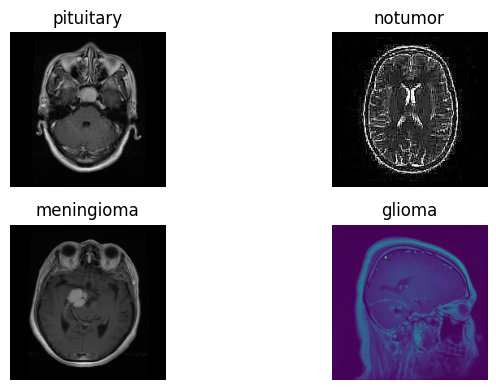

In [4]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

plt.figure(figsize=(8, 4))

for i, class_name in enumerate(classes):
    class_path = os.path.join(training_path, class_name)
    
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)
    
    image = mpimg.imread(image_path)
    
    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from PIL import Image

for class_name in classes:
    class_path = os.path.join(training_path, class_name)
    
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)
    
    image = Image.open(image_path)
    
    print(f"{class_name}:")
    print("  Image size:", image.size)
    print("  Image mode:", image.mode)
    print("  Format:", image.format)
    print()

pituitary:
  Image size: (512, 512)
  Image mode: RGB
  Format: JPEG

notumor:
  Image size: (192, 192)
  Image mode: RGB
  Format: JPEG

meningioma:
  Image size: (512, 512)
  Image mode: RGB
  Format: JPEG

glioma:
  Image size: (512, 512)
  Image mode: L
  Format: JPEG



In [6]:
def check_images(folder_path):
    total = 0
    corrupted = 0
    
    for class_name in os.listdir(folder_path):
        class_path = os.path.join(folder_path, class_name)
        
        if not os.path.isdir(class_path):
            continue
        
        for image_name in os.listdir(class_path):
            image_path = os.path.join(class_path, image_name)
            total += 1
            
            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception:
                corrupted += 1
                print("Problem:", image_path)
    
    return total, corrupted


train_total, train_corrupted = check_images(training_path)
test_total, test_corrupted = check_images(testing_path)

print("Training images:", train_total)
print("Corrupted training images:", train_corrupted)

print("\nTesting images:", test_total)
print("Corrupted testing images:", test_corrupted)

Training images: 5600
Corrupted training images: 0

Testing images: 1600
Corrupted testing images: 0


In [7]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training"
test_dir = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing"

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True,
    seed=42
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

print("Class names:", train_dataset.class_names)

Found 5600 files belonging to 4 classes.


I0000 00:00:1790865966.025451      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790865966.028521      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 1600 files belonging to 4 classes.
Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [9]:
for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 4)


In [10]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset_normalized = train_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_dataset_normalized = test_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

for images, labels in train_dataset_normalized.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [11]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset_normalized = train_dataset_normalized.cache().prefetch(
    buffer_size=AUTOTUNE
)

test_dataset_normalized = test_dataset_normalized.cache().prefetch(
    buffer_size=AUTOTUNE
)

print("Dataset pipeline optimization completed.")

Dataset pipeline optimization completed.


In [12]:
#cnn part is starting from here 

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True,
    seed=SEED,
    validation_split=0.20,
    subset="training"
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True,
    seed=SEED,
    validation_split=0.20,
    subset="validation"
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

print("Classes:", train_dataset.class_names)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [13]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda images, labels: (normalization_layer(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_dataset = validation_dataset.map(
    lambda images, labels: (normalization_layer(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    lambda images, labels: (normalization_layer(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

print("Training, validation, and testing datasets are ready.")

Training, validation, and testing datasets are ready.


In [14]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
], name="data_augmentation")

print("Data augmentation layer created successfully.")

Data augmentation layer created successfully.


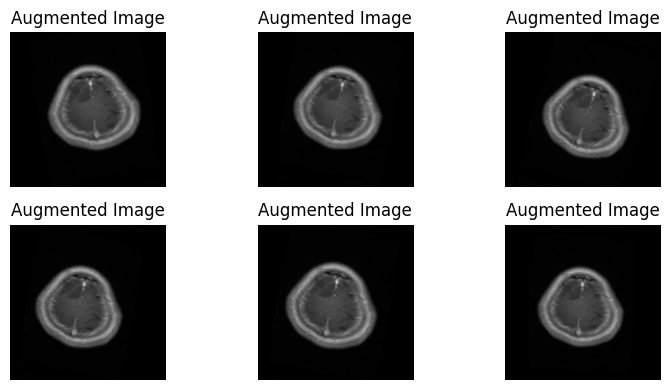

In [15]:
import matplotlib.pyplot as plt

for images, labels in train_dataset.take(1):
    sample_image = images[0]
    break

plt.figure(figsize=(8, 4))

for i in range(6):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    plt.subplot(2, 3, i + 1)
    plt.imshow(augmented_image)
    plt.axis("off")
    plt.title("Augmented Image")

plt.tight_layout()
plt.show()

In [16]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    
    # Input
    layers.Input(shape=(224, 224, 3)),
    
    # Data augmentation
    data_augmentation,
    
    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Convert feature maps into one vector
    layers.Flatten(),
    
    # Fully connected layer
    layers.Dense(128, activation="relu"),
    
    # Reduce overfitting
    layers.Dropout(0.5),
    
    # 4-class output
    layers.Dense(4, activation="softmax")
])

In [17]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


In [18]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = cnn_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 63ms/step - accuracy: 0.5574 - loss: 1.0478 - val_accuracy: 0.7009 - val_loss: 0.6911
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.7094 - loss: 0.7252 - val_accuracy: 0.8027 - val_loss: 0.5507
Epoch 3/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.7444 - loss: 0.6295 - val_accuracy: 0.7321 - val_loss: 0.6423
Epoch 4/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.7694 - loss: 0.5860 - val_accuracy: 0.7098 - val_loss: 0.9442
Epoch 5/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.7846 - loss: 0.5607 - val_accuracy: 0.7580 - val_loss: 0.6916
Epoch 6/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.7998 - loss: 0.5184 - val_accuracy: 0.8420 - val_loss: 0.3810
Epoch 7/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.8016 - loss: 0.4965 - val_accuracy: 0.7518 - val_loss: 0.6858
Epoch 8/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.8154 - loss: 0.4727 - val_acc

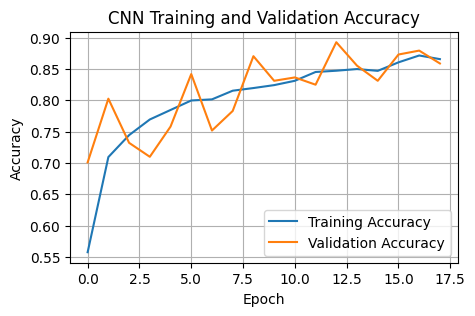

In [20]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(5, 3))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

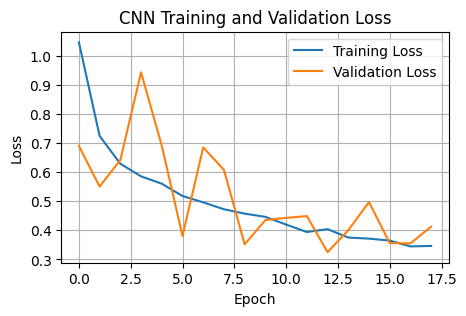

In [21]:
# Loss graph
plt.figure(figsize=(5, 3))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
test_loss, test_accuracy = cnn_model.evaluate(test_dataset, verbose=1)

print(f"\nCNN Test Loss: {test_loss:.4f}")
print(f"CNN Test Accuracy: {test_accuracy * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.7912 - loss: 0.9978

CNN Test Loss: 0.9978
CNN Test Accuracy: 79.12%


In [23]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = cnn_model.predict(images, verbose=0)
    
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total test samples:", len(y_true))
print("Total predictions:", len(y_pred))

Total test samples: 1600
Total predictions: 1600


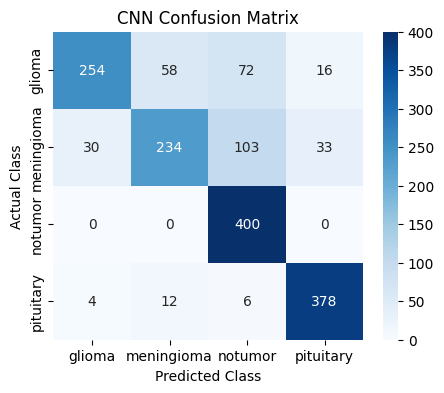

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ["glioma", "meningioma", "notumor", "pituitary"]

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [25]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

      glioma     0.8819    0.6350    0.7384       400
  meningioma     0.7697    0.5850    0.6648       400
     notumor     0.6885    1.0000    0.8155       400
   pituitary     0.8852    0.9450    0.9141       400

    accuracy                         0.7913      1600
   macro avg     0.8063    0.7912    0.7832      1600
weighted avg     0.8063    0.7913    0.7832      1600



In [26]:
cnn_model.save("/kaggle/working/cnn_baseline.keras")

print("CNN baseline model saved successfully.")

CNN baseline model saved successfully.


In [27]:
import os

model_path = "/kaggle/working/cnn_baseline.keras"

print("Model exists:", os.path.exists(model_path))
print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

Model exists: True
Model size: 127.88 MB


In [40]:
# start from here DenseNet121
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models

densenet_base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

densenet_base.trainable = False

print("New DenseNet121 base created.")
print("Frozen:", not densenet_base.trainable)

New DenseNet121 base created.
Frozen: True


In [41]:
densenet_model = models.Sequential([
    densenet_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(4, activation="softmax")
])

print("New DenseNet121 model created.")

New DenseNet121 model created.


In [42]:
densenet_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("DenseNet121 compiled successfully.")

DenseNet121 compiled successfully.


In [43]:
history_densenet = densenet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 51s 185ms/step - accuracy: 0.7625 - loss: 0.6320 - val_accuracy: 0.8830 - val_loss: 0.3373
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.8533 - loss: 0.3974 - val_accuracy: 0.8866 - val_loss: 0.3045
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.8768 - loss: 0.3349 - val_accuracy: 0.9098 - val_loss: 0.2484
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.8877 - loss: 0.3045 - val_accuracy: 0.9054 - val_loss: 0.2448
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.8935 - loss: 0.2725 - val_accuracy: 0.9179 - val_loss: 0.2139
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.9020 - loss: 0.2507 - val_accuracy: 0.9107 - val_loss: 0.2266
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.9118 - loss: 0.2372 - val_accuracy: 0.9196 - val_loss: 0.2046
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.9132 - loss: 0.2237 -

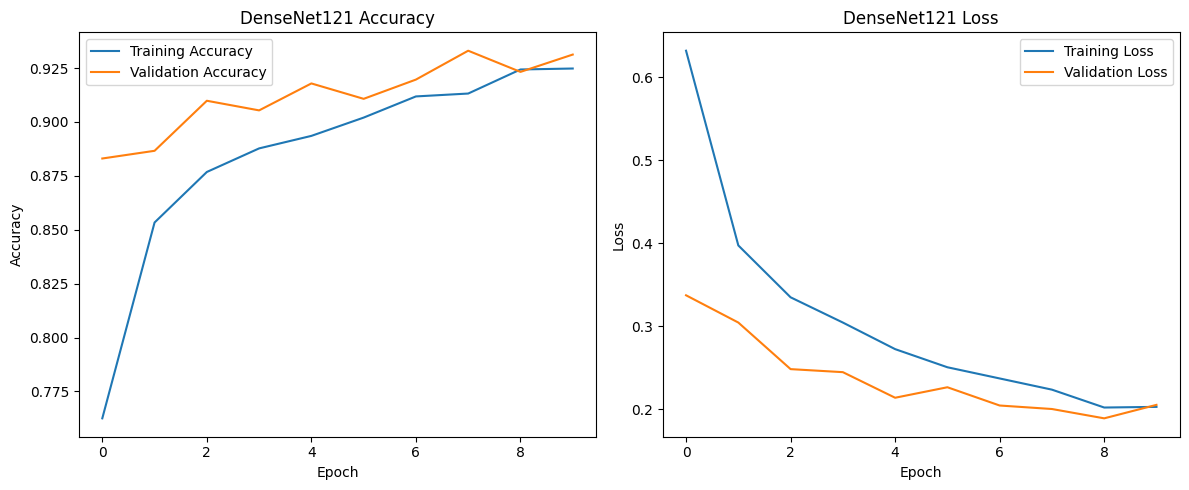

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_densenet.history["accuracy"], label="Training Accuracy")
plt.plot(history_densenet.history["val_accuracy"], label="Validation Accuracy")
plt.title("DenseNet121 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_densenet.history["loss"], label="Training Loss")
plt.plot(history_densenet.history["val_loss"], label="Validation Loss")
plt.title("DenseNet121 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [45]:
densenet_test_loss, densenet_test_accuracy = densenet_model.evaluate(
    test_dataset
)

print(f"DenseNet121 Test Loss: {densenet_test_loss:.4f}")
print(f"DenseNet121 Test Accuracy: {densenet_test_accuracy:.4f}")
print(f"DenseNet121 Test Accuracy: {densenet_test_accuracy * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.8656 - loss: 0.5131
DenseNet121 Test Loss: 0.5131
DenseNet121 Test Accuracy: 0.8656
DenseNet121 Test Accuracy: 86.56%


In [46]:
import numpy as np

y_true_densenet = []
y_pred_densenet = []

for images, labels in test_dataset:
    predictions = densenet_model.predict(images, verbose=0)

    y_true_densenet.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_densenet.extend(np.argmax(predictions, axis=1))

y_true_densenet = np.array(y_true_densenet)
y_pred_densenet = np.array(y_pred_densenet)

print("Total test images:", len(y_true_densenet))
print("Predictions generated:", len(y_pred_densenet))

Total test images: 1600
Predictions generated: 1600


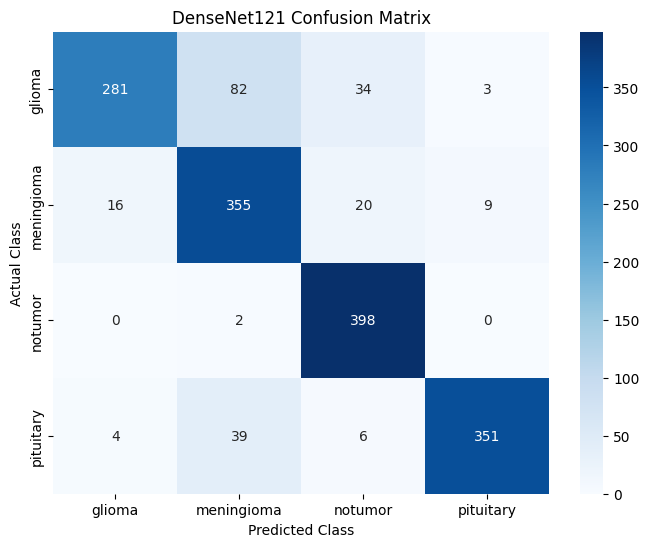

In [47]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_densenet = confusion_matrix(
    y_true_densenet,
    y_pred_densenet
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_densenet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("DenseNet121 Confusion Matrix")

plt.show()

In [48]:
from sklearn.metrics import classification_report

report_densenet = classification_report(
    y_true_densenet,
    y_pred_densenet,
    target_names=class_names
)

print(report_densenet)

              precision    recall  f1-score   support

      glioma       0.93      0.70      0.80       400
  meningioma       0.74      0.89      0.81       400
     notumor       0.87      0.99      0.93       400
   pituitary       0.97      0.88      0.92       400

    accuracy                           0.87      1600
   macro avg       0.88      0.87      0.86      1600
weighted avg       0.88      0.87      0.86      1600



In [49]:
densenet_model_path = "/kaggle/working/densenet121_transfer_learning.keras"

densenet_model.save(densenet_model_path)

print("DenseNet121 model saved successfully.")
print("Path:", densenet_model_path)

DenseNet121 model saved successfully.
Path: /kaggle/working/densenet121_transfer_learning.keras


In [50]:
print("Total DenseNet121 layers:", len(densenet_base.layers))

for i, layer in enumerate(densenet_base.layers[-20:]):
    print(i + len(densenet_base.layers) - 20, layer.name, layer.trainable)

Total DenseNet121 layers: 427
407 conv5_block14_1_bn False
408 conv5_block14_1_relu False
409 conv5_block14_2_conv False
410 conv5_block14_concat False
411 conv5_block15_0_bn False
412 conv5_block15_0_relu False
413 conv5_block15_1_conv False
414 conv5_block15_1_bn False
415 conv5_block15_1_relu False
416 conv5_block15_2_conv False
417 conv5_block15_concat False
418 conv5_block16_0_bn False
419 conv5_block16_0_relu False
420 conv5_block16_1_conv False
421 conv5_block16_1_bn False
422 conv5_block16_1_relu False
423 conv5_block16_2_conv False
424 conv5_block16_concat False
425 bn False
426 relu False


In [51]:
# Keep the whole DenseNet frozen first
densenet_base.trainable = True

# Freeze earlier layers
for layer in densenet_base.layers[:-50]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in densenet_base.layers[-50:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Trainable DenseNet layers:")

trainable_count = 0
for i, layer in enumerate(densenet_base.layers):
    if layer.trainable:
        trainable_count += 1
        print(i, layer.name)

print("Total trainable DenseNet layers:", trainable_count)

Trainable DenseNet layers:
377 conv5_block10_0_relu
378 conv5_block10_1_conv
380 conv5_block10_1_relu
381 conv5_block10_2_conv
382 conv5_block10_concat
384 conv5_block11_0_relu
385 conv5_block11_1_conv
387 conv5_block11_1_relu
388 conv5_block11_2_conv
389 conv5_block11_concat
391 conv5_block12_0_relu
392 conv5_block12_1_conv
394 conv5_block12_1_relu
395 conv5_block12_2_conv
396 conv5_block12_concat
398 conv5_block13_0_relu
399 conv5_block13_1_conv
401 conv5_block13_1_relu
402 conv5_block13_2_conv
403 conv5_block13_concat
405 conv5_block14_0_relu
406 conv5_block14_1_conv
408 conv5_block14_1_relu
409 conv5_block14_2_conv
410 conv5_block14_concat
412 conv5_block15_0_relu
413 conv5_block15_1_conv
415 conv5_block15_1_relu
416 conv5_block15_2_conv
417 conv5_block15_concat
419 conv5_block16_0_relu
420 conv5_block16_1_conv
422 conv5_block16_1_relu
423 conv5_block16_2_conv
424 conv5_block16_concat
426 relu
Total trainable DenseNet layers: 36


In [52]:
densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("DenseNet121 recompiled for fine-tuning.")

DenseNet121 recompiled for fine-tuning.


In [53]:
history_finetune = densenet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 55s 188ms/step - accuracy: 0.9402 - loss: 0.1639 - val_accuracy: 0.9429 - val_loss: 0.1621
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.9549 - loss: 0.1343 - val_accuracy: 0.9464 - val_loss: 0.1556
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 101ms/step - accuracy: 0.9578 - loss: 0.1275 - val_accuracy: 0.9491 - val_loss: 0.1504
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.9618 - loss: 0.1148 - val_accuracy: 0.9509 - val_loss: 0.1447
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.9641 - loss: 0.1066 - val_accuracy: 0.9563 - val_loss: 0.1384


In [54]:
finetuned_test_loss, finetuned_test_accuracy = densenet_model.evaluate(
    test_dataset
)

print(f"Fine-Tuned DenseNet121 Test Loss: {finetuned_test_loss:.4f}")
print(f"Fine-Tuned DenseNet121 Test Accuracy: {finetuned_test_accuracy:.4f}")
print(f"Fine-Tuned DenseNet121 Test Accuracy: {finetuned_test_accuracy * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.9094 - loss: 0.4832
Fine-Tuned DenseNet121 Test Loss: 0.4832
Fine-Tuned DenseNet121 Test Accuracy: 0.9094
Fine-Tuned DenseNet121 Test Accuracy: 90.94%


In [55]:
import numpy as np

y_true_finetuned = []
y_pred_finetuned = []

for images, labels in test_dataset:
    predictions = densenet_model.predict(images, verbose=0)

    y_true_finetuned.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred_finetuned.extend(
        np.argmax(predictions, axis=1)
    )

y_true_finetuned = np.array(y_true_finetuned)
y_pred_finetuned = np.array(y_pred_finetuned)

print("Total test images:", len(y_true_finetuned))
print("Predictions generated:", len(y_pred_finetuned))

Total test images: 1600
Predictions generated: 1600


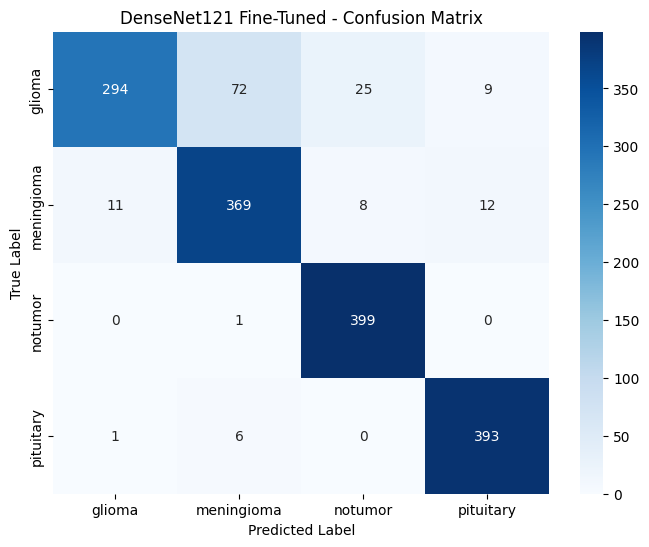

In [56]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm_finetuned = confusion_matrix(
    y_true_finetuned,
    y_pred_finetuned
)

# Display confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_finetuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("DenseNet121 Fine-Tuned - Confusion Matrix")

plt.show()

In [57]:
from sklearn.metrics import classification_report

report_finetuned = classification_report(
    y_true_finetuned,
    y_pred_finetuned,
    target_names=class_names,
    digits=4
)

print(report_finetuned)

              precision    recall  f1-score   support

      glioma     0.9608    0.7350    0.8329       400
  meningioma     0.8237    0.9225    0.8703       400
     notumor     0.9236    0.9975    0.9591       400
   pituitary     0.9493    0.9825    0.9656       400

    accuracy                         0.9094      1600
   macro avg     0.9143    0.9094    0.9070      1600
weighted avg     0.9143    0.9094    0.9070      1600



                           Model  Test Accuracy  Test Accuracy (%)
0                   CNN Baseline         0.8206              82.06
1  DenseNet121 Transfer Learning         0.8781              87.81
2         DenseNet121 Fine-Tuned         0.9013              90.13


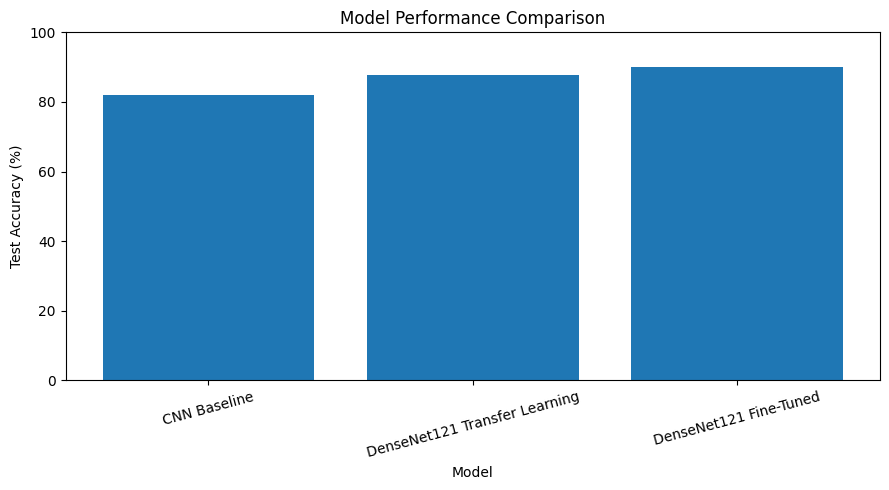

In [58]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "CNN Baseline",
        "DenseNet121 Transfer Learning",
        "DenseNet121 Fine-Tuned"
    ],
    "Test Accuracy": [
        0.8206,
        0.8781,
        0.9013
    ]
})

comparison["Test Accuracy (%)"] = comparison["Test Accuracy"] * 100

print(comparison)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Test Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Model Performance Comparison")
plt.ylim(0, 100)

plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

In [59]:
final_model_path = "/kaggle/working/densenet121_finetuned.keras"

densenet_model.save(final_model_path)

print("Final model saved successfully!")
print(final_model_path)

Final model saved successfully!
/kaggle/working/densenet121_finetuned.keras


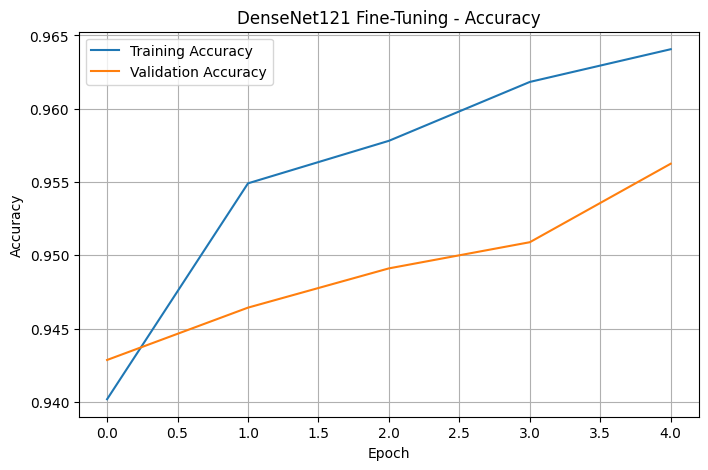

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_finetune.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_finetune.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet121 Fine-Tuning - Accuracy")

plt.legend()
plt.grid(True)

plt.show()

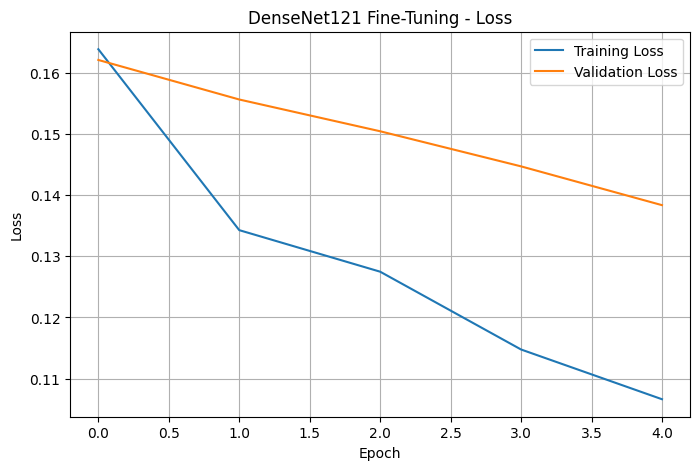

In [61]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_finetune.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_finetune.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet121 Fine-Tuning - Loss")

plt.legend()
plt.grid(True)

plt.show()

Step 42.1 — Load ResNet50

In [62]:
####Step 42.1 — Load ResNet50
from tensorflow.keras.applications import ResNet50

resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
resnet_base.trainable = False

print("ResNet50 loaded successfully!")
print("Total layers:", len(resnet_base.layers))


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 loaded successfully!
Total layers: 175


In [63]:
from tensorflow.keras import layers, models

resnet_model = models.Sequential([
    resnet_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(4, activation="softmax")
])

resnet_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [64]:
resnet_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 model compiled successfully!")

ResNet50 model compiled successfully!


In [65]:
history_resnet = resnet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 135ms/step - accuracy: 0.4268 - loss: 1.2482 - val_accuracy: 0.5616 - val_loss: 1.0523
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - accuracy: 0.5279 - loss: 1.0785 - val_accuracy: 0.6607 - val_loss: 0.9945
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - accuracy: 0.5679 - loss: 1.0249 - val_accuracy: 0.6634 - val_loss: 0.8972
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.6094 - loss: 0.9535 - val_accuracy: 0.7045 - val_loss: 0.8567
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.6353 - loss: 0.9007 - val_accuracy: 0.6946 - val_loss: 0.8137
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.6272 - loss: 0.8819 - val_accuracy: 0.7071 - val_loss: 0.7818
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.6500 - loss: 0.8446 - val_accuracy: 0.7098 - val_loss: 0.7235
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.6625 - loss: 0

In [66]:
resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    test_dataset
)

print("ResNet50 Test Loss:", resnet_test_loss)
print("ResNet50 Test Accuracy:", resnet_test_accuracy)
print(
    "ResNet50 Test Accuracy: "
    f"{resnet_test_accuracy * 100:.2f}%"
)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.6488 - loss: 1.0077
ResNet50 Test Loss: 1.0077435970306396
ResNet50 Test Accuracy: 0.6487500071525574
ResNet50 Test Accuracy: 64.88%


In [67]:

import numpy as np

y_true_resnet = []
y_pred_resnet = []

for images, labels in test_dataset:

    predictions = resnet_model.predict(
        images,
        verbose=0
    )

    y_true_resnet.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred_resnet.extend(
        np.argmax(predictions, axis=1)
    )

y_true_resnet = np.array(y_true_resnet)
y_pred_resnet = np.array(y_pred_resnet)

print("Total test images:", len(y_true_resnet))
print("Predictions generated:", len(y_pred_resnet))

Total test images: 1600
Predictions generated: 1600


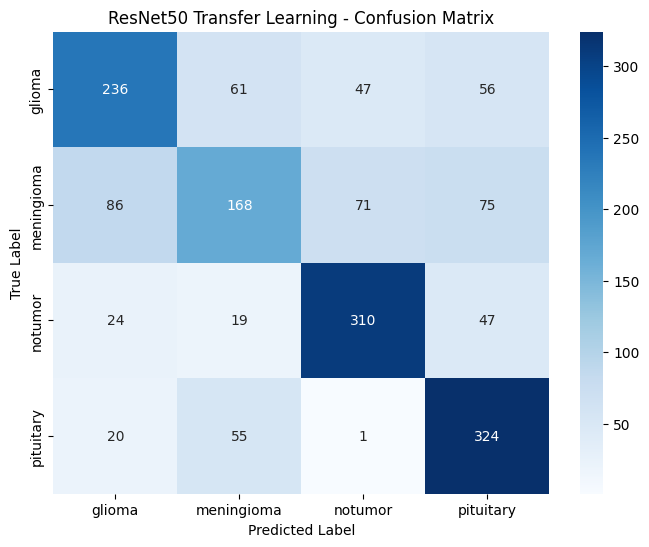

In [68]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet50 Transfer Learning - Confusion Matrix")

plt.show()

In [69]:
from sklearn.metrics import classification_report

resnet_report = classification_report(
    y_true_resnet,
    y_pred_resnet,
    target_names=class_names,
    digits=4
)

print(resnet_report)

              precision    recall  f1-score   support

      glioma     0.6448    0.5900    0.6162       400
  meningioma     0.5545    0.4200    0.4780       400
     notumor     0.7226    0.7750    0.7479       400
   pituitary     0.6454    0.8100    0.7184       400

    accuracy                         0.6488      1600
   macro avg     0.6418    0.6488    0.6401      1600
weighted avg     0.6418    0.6488    0.6401      1600



In [70]:
from tensorflow.keras import layers

resnet_base.trainable = True

# Freeze all layers except the last 50
for layer in resnet_base.layers[:-50]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in resnet_base.layers[-50:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_layers = sum(
    layer.trainable for layer in resnet_base.layers
)

frozen_layers = sum(
    not layer.trainable for layer in resnet_base.layers
)

print("Trainable layers:", trainable_layers)
print("Frozen layers:", frozen_layers)

Trainable layers: 35
Frozen layers: 140


In [71]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 recompiled for fine-tuning.")

ResNet50 recompiled for fine-tuning.


In [72]:
history_resnet_finetune = resnet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 45s 188ms/step - accuracy: 0.6699 - loss: 0.7957 - val_accuracy: 0.7152 - val_loss: 0.6391
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 160ms/step - accuracy: 0.7152 - loss: 0.6875 - val_accuracy: 0.7509 - val_loss: 0.5682
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 156ms/step - accuracy: 0.7388 - loss: 0.6481 - val_accuracy: 0.7937 - val_loss: 0.5281
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 156ms/step - accuracy: 0.7681 - loss: 0.5820 - val_accuracy: 0.8196 - val_loss: 0.4669
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 156ms/step - accuracy: 0.7804 - loss: 0.5387 - val_accuracy: 0.8196 - val_loss: 0.4505


In [73]:
resnet_finetune_test_loss, resnet_finetune_test_accuracy = resnet_model.evaluate(
    test_dataset
)

print("ResNet50 Fine-Tuned Test Loss:",
      resnet_finetune_test_loss)

print("ResNet50 Fine-Tuned Test Accuracy:",
      resnet_finetune_test_accuracy)

print(
    "ResNet50 Fine-Tuned Test Accuracy:",
    f"{resnet_finetune_test_accuracy * 100:.2f}%"
)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.7425 - loss: 0.8217
ResNet50 Fine-Tuned Test Loss: 0.8216752409934998
ResNet50 Fine-Tuned Test Accuracy: 0.7425000071525574
ResNet50 Fine-Tuned Test Accuracy: 74.25%


In [74]:
import numpy as np

y_true_resnet_finetuned = []
y_pred_resnet_finetuned = []

for images, labels in test_dataset:

    predictions = resnet_model.predict(
        images,
        verbose=0
    )

    y_true_resnet_finetuned.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred_resnet_finetuned.extend(
        np.argmax(predictions, axis=1)
    )

y_true_resnet_finetuned = np.array(
    y_true_resnet_finetuned
)

y_pred_resnet_finetuned = np.array(
    y_pred_resnet_finetuned
)

print(
    "Total test images:",
    len(y_true_resnet_finetuned)
)

print(
    "Predictions generated:",
    len(y_pred_resnet_finetuned)
)

Total test images: 1600
Predictions generated: 1600


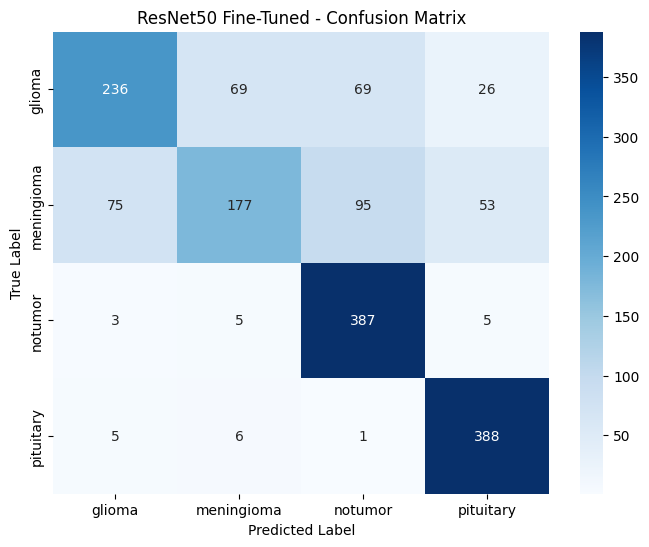

In [75]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_resnet_finetuned = confusion_matrix(
    y_true_resnet_finetuned,
    y_pred_resnet_finetuned
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_resnet_finetuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet50 Fine-Tuned - Confusion Matrix")

plt.show()

In [76]:
from sklearn.metrics import classification_report

resnet_finetuned_report = classification_report(
    y_true_resnet_finetuned,
    y_pred_resnet_finetuned,
    target_names=class_names,
    digits=4
)

print(resnet_finetuned_report)

              precision    recall  f1-score   support

      glioma     0.7398    0.5900    0.6565       400
  meningioma     0.6887    0.4425    0.5388       400
     notumor     0.7011    0.9675    0.8130       400
   pituitary     0.8220    0.9700    0.8899       400

    accuracy                         0.7425      1600
   macro avg     0.7379    0.7425    0.7246      1600
weighted avg     0.7379    0.7425    0.7246      1600



In [79]:
# Save fine-tuned ResNet50 model
resnet_model.save("/kaggle/working/resnet50_finetuned.keras")

print("ResNet50 fine-tuned model saved successfully.")

ResNet50 fine-tuned model saved successfully.


In [80]:
import os

model_path = "/kaggle/working/resnet50_finetuned.keras"

print("File exists:", os.path.exists(model_path))
print("File size:", os.path.getsize(model_path) / (1024 * 1024), "MB")

File exists: True
File size: 225.7532081604004 MB


In [86]:
print("train:", train_dataset_normalized)
print("test:", test_dataset_normalized)

train: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>
test: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>


In [87]:
validation_dataset_normalized = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=42,
    label_mode="categorical"
)

normalization_layer = tf.keras.layers.Rescaling(1./255)

validation_dataset_normalized = validation_dataset_normalized.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset_normalized = validation_dataset_normalized.prefetch(
    tf.data.AUTOTUNE
)

print("Validation dataset created successfully.")
print(validation_dataset_normalized)

Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Validation dataset created successfully.
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>


In [88]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

efficientnet_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnet_base.trainable = False

print("EfficientNetB0 base created.")
print("Frozen:", not efficientnet_base.trainable)

EfficientNetB0 base created.
Frozen: True


In [89]:
efficientnet_model = models.Sequential([
    efficientnet_base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])

efficientnet_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [90]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 compiled successfully.")

EfficientNetB0 compiled successfully.


In [95]:
history_efficientnet = efficientnet_model.fit(
    train_dataset_normalized,
    validation_data=validation_dataset_normalized,
    epochs=10
)

Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - accuracy: 0.2743 - loss: 1.3874 - val_accuracy: 0.2679 - val_loss: 1.3768
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.2598 - loss: 1.3912 - val_accuracy: 0.2679 - val_loss: 1.3764
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.2682 - loss: 1.3881 - val_accuracy: 0.2679 - val_loss: 1.3760
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.2671 - loss: 1.3874 - val_accuracy: 0.2679 - val_loss: 1.3757
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.2823 - loss: 1.3867 - val_accuracy: 0.2679 - val_loss: 1.3755
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.2766 - loss: 1.3883 - val_accuracy: 0.2679 - val_loss: 1.3751
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.2680 - loss: 1.3893 - val_accuracy: 0.2679 - val_loss: 1.3748
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.2714 - loss: 1.3852 - val_accu

In [96]:
print("Train:")
print(train_dataset_normalized)

print("\nValidation:")
print(validation_dataset_normalized)

print("\nTest:")
print(test_dataset_normalized)

Train:
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>

Validation:
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>

Test:
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>


In [97]:
x_batch, y_batch = next(iter(train_dataset_normalized))

print("Minimum pixel value:", tf.reduce_min(x_batch).numpy())
print("Maximum pixel value:", tf.reduce_max(x_batch).numpy())
print("Mean pixel value:", tf.reduce_mean(x_batch).numpy())
print("Labels shape:", y_batch.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Mean pixel value: 0.17052057
Labels shape: (32, 4)


In [99]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

efficientnet_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnet_base.trainable = False

efficientnet_model = models.Sequential([
    efficientnet_base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])

print("Fresh EfficientNetB0 model created.")
print("Base frozen:", not efficientnet_base.trainable)

efficientnet_model.summary()

Fresh EfficientNetB0 model created.
Base frozen: True


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [100]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 compiled successfully.")

EfficientNetB0 compiled successfully.


In [101]:
train_dataset_efficientnet = train_dataset_normalized.map(
    lambda x, y: (x * 255.0, y)
).prefetch(tf.data.AUTOTUNE)

validation_dataset_efficientnet = validation_dataset_normalized.map(
    lambda x, y: (x * 255.0, y)
).prefetch(tf.data.AUTOTUNE)

test_dataset_efficientnet = test_dataset_normalized.map(
    lambda x, y: (x * 255.0, y)
).prefetch(tf.data.AUTOTUNE)

print("EfficientNet datasets prepared.")

EfficientNet datasets prepared.


In [102]:
x_batch, y_batch = next(iter(train_dataset_efficientnet))

print("Minimum:", tf.reduce_min(x_batch).numpy())
print("Maximum:", tf.reduce_max(x_batch).numpy())
print("Mean:", tf.reduce_mean(x_batch).numpy())
print("Labels:", y_batch.shape)

Minimum: 0.0
Maximum: 255.0
Mean: 43.48275
Labels: (32, 4)


In [103]:
history_efficientnet = efficientnet_model.fit(
    train_dataset_efficientnet,
    validation_data=validation_dataset_efficientnet,
    epochs=10
)

Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 36s 91ms/step - accuracy: 0.4257 - loss: 1.2678 - val_accuracy: 0.6938 - val_loss: 0.9630
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.6746 - loss: 0.9154 - val_accuracy: 0.7839 - val_loss: 0.7390
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - accuracy: 0.7364 - loss: 0.7640 - val_accuracy: 0.8125 - val_loss: 0.6218
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - accuracy: 0.7698 - loss: 0.6706 - val_accuracy: 0.8384 - val_loss: 0.5489
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.7932 - loss: 0.6081 - val_accuracy: 0.8518 - val_loss: 0.4982
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.8118 - loss: 0.5619 - val_accuracy: 0.8643 - val_loss: 0.4601
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - accuracy: 0.8166 - loss: 0.5300 - val_accuracy: 0.8679 - val_loss: 0.4305
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.8314 - loss: 0.5030 - val_acc

In [104]:
efficientnet_test_loss, efficientnet_test_accuracy = efficientnet_model.evaluate(
    test_dataset_efficientnet,
    verbose=1
)

print(f"EfficientNetB0 Test Loss: {efficientnet_test_loss:.4f}")
print(f"EfficientNetB0 Test Accuracy: {efficientnet_test_accuracy * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.8106 - loss: 0.5344
EfficientNetB0 Test Loss: 0.5344
EfficientNetB0 Test Accuracy: 81.06%


In [105]:
# Unfreeze the top layers of EfficientNetB0
efficientnet_base.trainable = True

# Freeze the earlier layers
for layer in efficientnet_base.layers[:-30]:
    layer.trainable = False

print("EfficientNetB0 prepared for fine-tuning.")
print("Trainable layers:", sum(layer.trainable for layer in efficientnet_base.layers))

EfficientNetB0 prepared for fine-tuning.
Trainable layers: 30


In [106]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 recompiled for fine-tuning.")

EfficientNetB0 recompiled for fine-tuning.


In [107]:
history_efficientnet_finetune = efficientnet_model.fit(
    train_dataset_efficientnet,
    validation_data=validation_dataset_efficientnet,
    epochs=5
)

Epoch 1/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 46s 93ms/step - accuracy: 0.7664 - loss: 0.6682 - val_accuracy: 0.8830 - val_loss: 0.3640
Epoch 2/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.8289 - loss: 0.5057 - val_accuracy: 0.9009 - val_loss: 0.3328
Epoch 3/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - accuracy: 0.8523 - loss: 0.4404 - val_accuracy: 0.9196 - val_loss: 0.2954
Epoch 4/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.8666 - loss: 0.3943 - val_accuracy: 0.9330 - val_loss: 0.2631
Epoch 5/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.8712 - loss: 0.3622 - val_accuracy: 0.9393 - val_loss: 0.2370


In [109]:
efficientnet_finetune_test_loss, efficientnet_finetune_test_accuracy = efficientnet_model.evaluate(
    test_dataset_efficientnet,
    verbose=1
)

print(f"EfficientNetB0 Fine-Tuned Test Loss: {efficientnet_finetune_test_loss:.4f}")
print(f"EfficientNetB0 Fine-Tuned Test Accuracy: {efficientnet_finetune_test_accuracy * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.8431 - loss: 0.4671
EfficientNetB0 Fine-Tuned Test Loss: 0.4671
EfficientNetB0 Fine-Tuned Test Accuracy: 84.31%


In [110]:
efficientnet_model.save(
    "/kaggle/working/efficientnetb0_finetuned.keras"
)

print("EfficientNetB0 fine-tuned model saved successfully.")

EfficientNetB0 fine-tuned model saved successfully.


In [111]:
import os

model_path = "/kaggle/working/efficientnetb0_finetuned.keras"

print("File exists:", os.path.exists(model_path))
print("File size:", os.path.getsize(model_path) / (1024 * 1024), "MB")

File exists: True
File size: 27.744893074035645 MB


In [112]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

RESULTS_DIR = "/kaggle/working/results"
CM_DIR = os.path.join(RESULTS_DIR, "confusion_matrices")

os.makedirs(CM_DIR, exist_ok=True)

print("Results folders created.")
print(RESULTS_DIR)

Results folders created.
/kaggle/working/results


In [113]:
model_comparison = pd.DataFrame({
    "Model": [
        "CNN Baseline",
        "DenseNet121 Transfer Learning",
        "DenseNet121 Fine-Tuned",
        "ResNet50 Fine-Tuned",
        "EfficientNetB0 Fine-Tuned"
    ],
    "Test Accuracy": [
        0.8206,
        0.8781,
        0.9013,
        0.7425,
        0.8431
    ]
})

model_comparison["Test Accuracy (%)"] = (
    model_comparison["Test Accuracy"] * 100
)

comparison_path = os.path.join(
    RESULTS_DIR,
    "model_comparison.csv"
)

model_comparison.to_csv(
    comparison_path,
    index=False
)

print(model_comparison)
print("\nSaved:", comparison_path)

                           Model  Test Accuracy  Test Accuracy (%)
0                   CNN Baseline         0.8206              82.06
1  DenseNet121 Transfer Learning         0.8781              87.81
2         DenseNet121 Fine-Tuned         0.9013              90.13
3            ResNet50 Fine-Tuned         0.7425              74.25
4      EfficientNetB0 Fine-Tuned         0.8431              84.31

Saved: /kaggle/working/results/model_comparison.csv


In [121]:
classification_reports = {}

# CNN
if "y_true" in globals() and "y_pred" in globals():
    classification_reports["CNN Baseline"] = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        output_dict=True
    )

# DenseNet121 Transfer Learning
if "y_true_densenet" in globals() and "y_pred_densenet" in globals():
    classification_reports["DenseNet121 Transfer Learning"] = classification_report(
        y_true_densenet,
        y_pred_densenet,
        target_names=class_names,
        output_dict=True
    )

# DenseNet121 Fine-Tuned
if "y_true_finetuned" in globals() and "y_pred_finetuned" in globals():
    classification_reports["DenseNet121 Fine-Tuned"] = classification_report(
        y_true_finetuned,
        y_pred_finetuned,
        target_names=class_names,
        output_dict=True
    )

print("Reports available for:")
for model_name in classification_reports:
    print("-", model_name)

Reports available for:
- CNN Baseline
- DenseNet121 Transfer Learning
- DenseNet121 Fine-Tuned


In [116]:
y_true_resnet = []
y_pred_resnet = []

for images, labels in test_dataset:
    predictions = resnet_model.predict(images, verbose=0)

    y_true_resnet.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred_resnet.extend(
        np.argmax(predictions, axis=1)
    )

y_true_resnet = np.array(y_true_resnet)
y_pred_resnet = np.array(y_pred_resnet)

print("ResNet50 test images:", len(y_true_resnet))
print("ResNet50 predictions:", len(y_pred_resnet))

ResNet50 test images: 1600
ResNet50 predictions: 1600


In [117]:
classification_reports["ResNet50 Fine-Tuned"] = classification_report(
    y_true_resnet,
    y_pred_resnet,
    target_names=class_names,
    output_dict=True
)

print("ResNet50 classification report added.")

ResNet50 classification report added.


In [118]:
y_true_efficientnet = []
y_pred_efficientnet = []

for images, labels in test_dataset_efficientnet:
    predictions = efficientnet_model.predict(images, verbose=0)

    y_true_efficientnet.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred_efficientnet.extend(
        np.argmax(predictions, axis=1)
    )

y_true_efficientnet = np.array(y_true_efficientnet)
y_pred_efficientnet = np.array(y_pred_efficientnet)

print("EfficientNetB0 test images:", len(y_true_efficientnet))
print("EfficientNetB0 predictions:", len(y_pred_efficientnet))

EfficientNetB0 test images: 1600
EfficientNetB0 predictions: 1600


In [119]:
classification_reports["EfficientNetB0 Fine-Tuned"] = classification_report(
    y_true_efficientnet,
    y_pred_efficientnet,
    target_names=class_names,
    output_dict=True
)

print("EfficientNetB0 classification report added.")

EfficientNetB0 classification report added.


In [120]:
reports_path = os.path.join(
    RESULTS_DIR,
    "classification_reports.json"
)

with open(reports_path, "w") as f:
    json.dump(
        classification_reports,
        f,
        indent=4
    )

print("All classification reports saved successfully.")
print(reports_path)

All classification reports saved successfully.
/kaggle/working/results/classification_reports.json


In [122]:
prediction_sets = {
    "cnn": (y_true, y_pred),
    "densenet121_transfer": (
        y_true_densenet,
        y_pred_densenet
    ),
    "densenet121_finetuned": (
        y_true_finetuned,
        y_pred_finetuned
    ),
    "resnet50_finetuned": (
        y_true_resnet,
        y_pred_resnet
    ),
    "efficientnetb0_finetuned": (
        y_true_efficientnet,
        y_pred_efficientnet
    )
}

for model_name, (true_labels, predicted_labels) in prediction_sets.items():

    cm = confusion_matrix(
        true_labels,
        predicted_labels
    )

    cm_path = os.path.join(
        CM_DIR,
        f"{model_name}.json"
    )

    with open(cm_path, "w") as f:
        json.dump(
            {
                "classes": class_names,
                "matrix": cm.tolist()
            },
            f,
            indent=4
        )

    print(f"Saved: {model_name}.json")

Saved: cnn.json
Saved: densenet121_transfer.json
Saved: densenet121_finetuned.json
Saved: resnet50_finetuned.json
Saved: efficientnetb0_finetuned.json


In [123]:
print("DenseNet121 fine-tuned model exists:",
      'densenet_model' in globals())

if 'densenet_model' in globals():
    print("DenseNet121 model loaded in memory.")

DenseNet121 fine-tuned model exists: True
DenseNet121 model loaded in memory.


In [127]:
import os

MODELS_DIR = "/kaggle/working"
os.makedirs(MODELS_DIR, exist_ok=True)

final_model_path = os.path.join(
    MODELS_DIR,
    "final_brain_tumor_model.keras"
)

densenet_model.save(final_model_path)

print("Final model saved successfully.")
print("Path:", final_model_path)
print("Size:", os.path.getsize(final_model_path) / (1024 * 1024), "MB")

Final model saved successfully.
Path: /kaggle/working/final_brain_tumor_model.keras
Size: 39.41286087036133 MB


In [128]:
final_model = tf.keras.models.load_model(
    final_model_path
)

print("Final model loaded successfully.")
print("Model input shape:", final_model.input_shape)
print("Model output shape:", final_model.output_shape)

Final model loaded successfully.
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 4)


In [129]:
for layer in final_model.layers:
    print(layer.name, layer.__class__.__name__)

densenet121 Functional
global_average_pooling2d_1 GlobalAveragePooling2D
dense_4 Dense
dropout_2 Dropout
dense_5 Dense


In [130]:
densenet_base_model = final_model.get_layer("densenet121")

for layer in densenet_base_model.layers[-30:]:
    print(layer.name, layer.__class__.__name__, layer.output.shape)

conv5_block13_0_bn BatchNormalization (None, 7, 7, 896)
conv5_block13_0_relu Activation (None, 7, 7, 896)
conv5_block13_1_conv Conv2D (None, 7, 7, 128)
conv5_block13_1_bn BatchNormalization (None, 7, 7, 128)
conv5_block13_1_relu Activation (None, 7, 7, 128)
conv5_block13_2_conv Conv2D (None, 7, 7, 32)
conv5_block13_concat Concatenate (None, 7, 7, 928)
conv5_block14_0_bn BatchNormalization (None, 7, 7, 928)
conv5_block14_0_relu Activation (None, 7, 7, 928)
conv5_block14_1_conv Conv2D (None, 7, 7, 128)
conv5_block14_1_bn BatchNormalization (None, 7, 7, 128)
conv5_block14_1_relu Activation (None, 7, 7, 128)
conv5_block14_2_conv Conv2D (None, 7, 7, 32)
conv5_block14_concat Concatenate (None, 7, 7, 960)
conv5_block15_0_bn BatchNormalization (None, 7, 7, 960)
conv5_block15_0_relu Activation (None, 7, 7, 960)
conv5_block15_1_conv Conv2D (None, 7, 7, 128)
conv5_block15_1_bn BatchNormalization (None, 7, 7, 128)
conv5_block15_1_relu Activation (None, 7, 7, 128)
conv5_block15_2_conv Conv2D (None,

In [131]:
# Grad-CAM target layer
gradcam_layer_name = "conv5_block16_2_conv"

gradcam_layer = densenet_base_model.get_layer(gradcam_layer_name)

print("Grad-CAM target layer:", gradcam_layer.name)
print("Layer type:", gradcam_layer.__class__.__name__)
print("Output shape:", gradcam_layer.output.shape)

Grad-CAM target layer: conv5_block16_2_conv
Layer type: Conv2D
Output shape: (None, 7, 7, 32)


In [141]:
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):

    # Get the DenseNet121 backbone
    densenet_base_model = model.get_layer("densenet121")

    # Create a model that gives:
    # 1. Convolutional feature maps
    # 2. Final predictions
    grad_model = tf.keras.models.Model(
        inputs=densenet_base_model.input,
        outputs=[
            densenet_base_model.get_layer(last_conv_layer_name).output,
            densenet_base_model.output
        ]
    )

    with tf.GradientTape() as tape:

        # Get DenseNet feature maps and its final output
        conv_outputs, backbone_output = grad_model(
            img_array,
            training=False
        )

        # Pass backbone output through the remaining layers
        x = backbone_output

        for layer in model.layers[1:]:
            x = layer(x, training=False)

        predictions = x

        # Select class
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    # Calculate gradients
    grads = tape.gradient(class_channel, conv_outputs)

    # Average gradients across height and width
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weight feature maps using gradients
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    # Keep positive activations
    heatmap = tf.maximum(heatmap, 0)

    # Normalize between 0 and 1
    heatmap = heatmap / (
        tf.reduce_max(heatmap) +
        tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [142]:
for images, labels in test_dataset_normalized.take(1):
    sample_image = images[0:1]
    sample_label = labels[0]

heatmap = make_gradcam_heatmap(
    sample_image,
    final_model,
    gradcam_layer_name
)

print("Heatmap generated successfully.")
print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())

Heatmap generated successfully.
Heatmap shape: (7, 7)
Heatmap minimum: 0.0
Heatmap maximum: 0.9999835


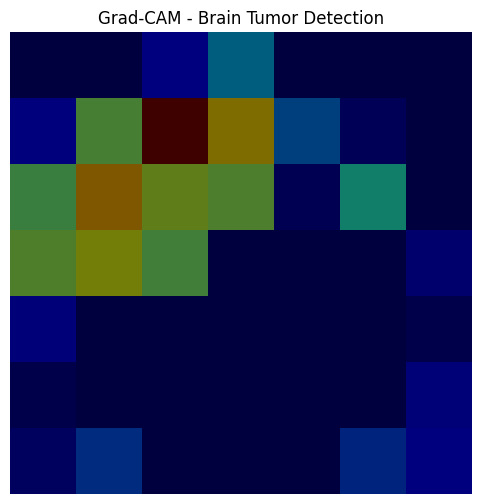

In [143]:
import matplotlib.pyplot as plt

# Convert image from 0–1 back to displayable format
display_image = sample_image[0].numpy()

plt.figure(figsize=(6, 6))
plt.imshow(display_image)
plt.imshow(heatmap, cmap="jet", alpha=0.5)
plt.axis("off")
plt.title("Grad-CAM - Brain Tumor Detection")
plt.show()

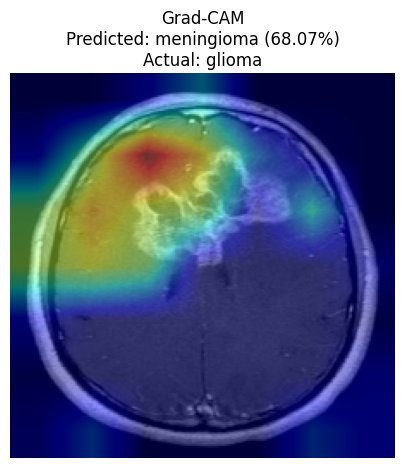

Predicted class: meningioma
Confidence: 68.07%
Actual class: glioma


In [146]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# Class names from the Brain Tumor MRI dataset
class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

# Get prediction
prediction = final_model.predict(sample_image, verbose=0)

predicted_index = np.argmax(prediction[0])
confidence = prediction[0][predicted_index] * 100

predicted_class = class_names[predicted_index]
actual_class = class_names[np.argmax(sample_label.numpy())]

# Resize 7x7 Grad-CAM heatmap to 224x224
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

# Original MRI image
display_image = sample_image[0].numpy()

# Visualization
plt.figure(figsize=(5, 5))

plt.imshow(display_image)

plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    f"Grad-CAM\n"
    f"Predicted: {predicted_class} ({confidence:.2f}%)\n"
    f"Actual: {actual_class}"
)

plt.show()

print("Predicted class:", predicted_class)
print("Confidence:", f"{confidence:.2f}%")
print("Actual class:", actual_class)

In [147]:
# Display probability for every class

print("Prediction probabilities:")
print("-" * 35)

for class_name, probability in zip(class_names, prediction[0]):
    print(f"{class_name:12s}: {probability * 100:.2f}%")

print("-" * 35)
print(f"Predicted class : {predicted_class}")
print(f"Confidence      : {confidence:.2f}%")
print(f"Actual class    : {actual_class}")

Prediction probabilities:
-----------------------------------
glioma      : 0.77%
meningioma  : 68.07%
notumor     : 31.00%
pituitary   : 0.16%
-----------------------------------
Predicted class : meningioma
Confidence      : 68.07%
Actual class    : glioma


In [148]:
import numpy as np

# Search the existing test dataset for a correctly classified image
correct_found = False

for images, labels in test_dataset_normalized:

    predictions = final_model.predict(images, verbose=0)

    predicted_indices = np.argmax(predictions, axis=1)
    actual_indices = np.argmax(labels.numpy(), axis=1)

    # Find correctly classified image positions
    correct_positions = np.where(
        predicted_indices == actual_indices
    )[0]

    if len(correct_positions) > 0:

        # Take the first correctly classified image
        idx = correct_positions[0]

        sample_image = images[idx:idx+1]
        sample_label = labels[idx]
        
        predicted_index = predicted_indices[idx]
        confidence = predictions[idx][predicted_index] * 100

        predicted_class = class_names[predicted_index]
        actual_class = class_names[actual_indices[idx]]

        correct_found = True
        break

if correct_found:
    print("Correctly classified image found.")
    print("-" * 40)
    print("Predicted class:", predicted_class)
    print("Confidence:", f"{confidence:.2f}%")
    print("Actual class:", actual_class)
else:
    print("No correctly classified image found.")

Correctly classified image found.
----------------------------------------
Predicted class: glioma
Confidence: 100.00%
Actual class: glioma


In [149]:
# Generate Grad-CAM for the correctly classified image

heatmap = make_gradcam_heatmap(
    sample_image,
    final_model,
    gradcam_layer_name
)

print("Grad-CAM generated successfully.")
print("Heatmap shape:", heatmap.shape)
print("Predicted:", predicted_class)
print("Confidence:", f"{confidence:.2f}%")
print("Actual:", actual_class)

Grad-CAM generated successfully.
Heatmap shape: (7, 7)
Predicted: glioma
Confidence: 100.00%
Actual: glioma


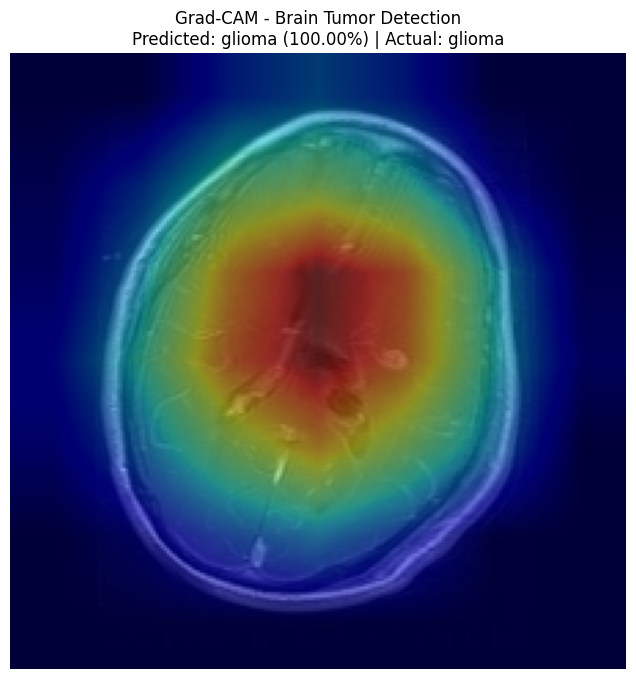

In [150]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# Resize 7x7 heatmap to 224x224
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

# Original MRI image
display_image = sample_image[0].numpy()

# Create visualization
plt.figure(figsize=(8, 8))

plt.imshow(display_image)

plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    f"Grad-CAM - Brain Tumor Detection\n"
    f"Predicted: {predicted_class} ({confidence:.2f}%) | "
    f"Actual: {actual_class}"
)

plt.show()

In [151]:
import os
import json

CONFIG_DIR = "/kaggle/working/config"
os.makedirs(CONFIG_DIR, exist_ok=True)

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

class_names_config = {
    "class_names": class_names,
    "num_classes": len(class_names)
}

class_names_path = os.path.join(
    CONFIG_DIR,
    "class_names.json"
)

with open(class_names_path, "w") as f:
    json.dump(class_names_config, f, indent=4)

print("Class names configuration saved successfully.")
print(class_names_path)

# Verify
with open(class_names_path, "r") as f:
    print(json.load(f))

Class names configuration saved successfully.
/kaggle/working/config/class_names.json
{'class_names': ['glioma', 'meningioma', 'notumor', 'pituitary'], 'num_classes': 4}


In [152]:
import os
import json

# Grad-CAM configuration directory
GRADCAM_DIR = "/kaggle/working/gradcam"
os.makedirs(GRADCAM_DIR, exist_ok=True)

gradcam_config = {
    "method": "Grad-CAM",
    "model": "final_brain_tumor_model.keras",
    "backbone": "DenseNet121",
    "target_layer": "conv5_block16_2_conv",
    "target_layer_type": "Conv2D",
    "feature_map_shape": [7, 7, 32],
    "input_size": [224, 224, 3],
    "heatmap_size": [7, 7],
    "display_heatmap_size": [224, 224],
    "normalization": "0-1",
    "positive_activations_only": True,
    "overlay_alpha": 0.45
}

gradcam_config_path = os.path.join(
    GRADCAM_DIR,
    "gradcam_config.json"
)

with open(gradcam_config_path, "w") as f:
    json.dump(gradcam_config, f, indent=4)

print("Grad-CAM configuration saved successfully.")
print(gradcam_config_path)

Grad-CAM configuration saved successfully.
/kaggle/working/gradcam/gradcam_config.json


In [153]:
import os
import json

CONFIG_DIR = "/kaggle/working/config"
os.makedirs(CONFIG_DIR, exist_ok=True)

preprocessing_config = {
    "image_size": [224, 224],
    "channels": 3,
    "color_mode": "rgb",
    "rescaling": "1/255",
    "input_range": [0, 1],
    "model_input_shape": [224, 224, 3],
    "batch_dimension": True
}

preprocessing_config_path = os.path.join(
    CONFIG_DIR,
    "preprocessing_config.json"
)

with open(preprocessing_config_path, "w") as f:
    json.dump(preprocessing_config, f, indent=4)

print("Preprocessing configuration saved successfully.")
print(preprocessing_config_path)

# Verify
with open(preprocessing_config_path, "r") as f:
    print(json.load(f))

Preprocessing configuration saved successfully.
/kaggle/working/config/preprocessing_config.json
{'image_size': [224, 224], 'channels': 3, 'color_mode': 'rgb', 'rescaling': '1/255', 'input_range': [0, 1], 'model_input_shape': [224, 224, 3], 'batch_dimension': True}
